# 🦟 VectorIA
## Análisis Exploratorio de Datos (EDA)
### Dataset 9: Dengue semanal por provincia — Bonus LSTM

**Proyecto:** VectorIA — Asistente Inteligente para la Vigilancia del Dengue en Costa Rica  
**Módulo:** Bonus — Predicción provincial de casos semanales de dengue  
**Dataset:** `vectoria_dengue_semanal.csv`  
**Fuente:** Archivo entregado por el profesor  
**Período:** 2014–2025 · 7 provincias  


**Objetivo:** estudiar estructura, calidad, distribución geográfica, tendencias semanales, estacionalidad, relaciones con el clima, valores faltantes y rezagos, para documentar las características del dataset antes del modelado opcional de cuatro semanas por provincia.

---

## 1. Importación de librerías

Se cargan las librerías necesarias una sola vez, sin importar herramientas de entrenamiento de modelos.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 105

## 2. Carga y exploración inicial del dataset

Se lee el CSV original con la ruta exacta del proyecto. La fecha se convierte a un tipo temporal y las filas se ordenan por provincia y fecha.

In [2]:
ruta = Path(r"C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\InteligenciaArticial\Proyecto\P2\VectorIA\data\raw\VectorIA-datos")
archivo = ruta / "vectoria_dengue_semanal.csv"
datos = pd.read_csv(archivo, parse_dates=["fecha_inicio_semana"])
datos = datos.sort_values(["provincia", "fecha_inicio_semana"]).reset_index(drop=True)

print("Dataset:", archivo.name)
print("Primeras filas:")
display(datos.head(8))
print("Últimas filas:")
display(datos.tail(8))

Dataset: vectoria_dengue_semanal.csv
Primeras filas:


,fecha_inicio_semana,anio,semana_epi,provincia,region_climatica,poblacion,casos_dengue,tasa_100k,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
0,2014-01-05,2014,2,Alajuela,Valle Central,1100000,27,2.45,0.0,27.1,18.9,58.1
1,2014-01-12,2014,3,Alajuela,Valle Central,1100000,10,0.91,0.0,27.3,17.6,64.0
2,2014-01-19,2014,4,Alajuela,Valle Central,1100000,32,2.91,0.0,28.7,18.8,59.4
3,2014-01-26,2014,5,Alajuela,Valle Central,1100000,22,2.00,0.0,28.9,19.2,65.4
4,2014-02-02,2014,6,Alajuela,Valle Central,1100000,15,1.36,0.0,29.3,19.0,65.4
5,2014-02-09,2014,7,Alajuela,Valle Central,1100000,6,0.55,0.0,29.0,18.6,62.0
6,2014-02-16,2014,8,Alajuela,Valle Central,1100000,39,3.55,0.0,28.9,18.4,64.0
7,2014-02-23,2014,9,Alajuela,Valle Central,1100000,24,2.18,0.0,29.6,19.0,62.6


Últimas filas:


,fecha_inicio_semana,anio,semana_epi,provincia,region_climatica,poblacion,casos_dengue,tasa_100k,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
4374,2025-11-09,2025,46,San José,Valle Central,1660000,30,1.81,8.2,24.6,16.9,70.8
4375,2025-11-16,2025,47,San José,Valle Central,1660000,37,2.23,14.2,25.9,17.9,72.8
4376,2025-11-23,2025,48,San José,Valle Central,1660000,45,2.71,25.2,24.4,17.2,75.1
4377,2025-11-30,2025,49,San José,Valle Central,1660000,31,1.87,2.4,25.8,17.4,69.4
4378,2025-12-07,2025,50,San José,Valle Central,1660000,29,1.75,0.9,26.8,17.9,66.4
4379,2025-12-14,2025,51,San José,Valle Central,1660000,14,0.84,16.6,26.3,17.0,71.2
4380,2025-12-21,2025,52,San José,Valle Central,1660000,20,1.20,7.1,26.2,17.0,65.4
4381,2025-12-28,2025,1,San José,Valle Central,1660000,5,0.30,2.9,26.0,17.4,69.1


## 3. Dimensiones del dataset

Se identifica cuántos registros y variables contiene el conjunto de datos.

In [3]:
filas, columnas = datos.shape
print("Número de filas:", filas)
print("Número de columnas:", columnas)
display(pd.DataFrame({"Variable": datos.columns, "Tipo": datos.dtypes.astype(str).values}))

Número de filas: 4382
Número de columnas: 12


,Variable,Tipo
0,fecha_inicio_semana,datetime64[us]
1,anio,int64
2,semana_epi,int64
3,provincia,str
4,region_climatica,str
5,poblacion,int64
6,casos_dengue,int64
7,tasa_100k,float64
8,lluvia_mm,float64
9,temp_max_c,float64


## 4. Identificación de variables y tipos de datos

Se clasifican las variables numéricas, categóricas y temporales del archivo.

In [4]:
print("Tipos de datos:")
datos.info()
columnas_numericas = datos.select_dtypes(include="number").columns.tolist()
columnas_categoricas = datos.select_dtypes(include=["object", "category"]).columns.tolist()
print("\nNuméricas:", columnas_numericas)
print("Categóricas:", columnas_categoricas)
print("Temporales:", datos.select_dtypes(include="datetime").columns.tolist())

Tipos de datos:
<class 'pandas.DataFrame'>
RangeIndex: 4382 entries, 0 to 4381
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   fecha_inicio_semana  4382 non-null   datetime64[us]
 1   anio                 4382 non-null   int64         
 2   semana_epi           4382 non-null   int64         
 3   provincia            4382 non-null   str           
 4   region_climatica     4382 non-null   str           
 5   poblacion            4382 non-null   int64         
 6   casos_dengue         4382 non-null   int64         
 7   tasa_100k            4382 non-null   float64       
 8   lluvia_mm            4347 non-null   float64       
 9   temp_max_c           4348 non-null   float64       
 10  temp_min_c           4382 non-null   float64       
 11  humedad_rel_pct      4353 non-null   float64       
dtypes: datetime64[us](1), float64(5), int64(4), str(2)
memory usage: 410.9 KB

Numéricas:

C:\Users\andre\AppData\Local\Temp\ipykernel_17796\3508182195.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_categoricas = datos.select_dtypes(include=["object", "category"]).columns.tolist()


## 5. Estadísticas descriptivas

Se calculan los estadísticos básicos para identificar valores extremos y rangos generales.

In [5]:
display(datos.describe(include="number").T.round(2))
print("Resumen de variables categóricas:")
display(datos.describe(include=["object"]).T)

,count,mean,std,min,25%,50%,75%,max
anio,4382.0,2019.50,3.45,2014.0,2017.00,2019.50,2023.0,2025.00
semana_epi,4382.0,26.58,15.06,1.0,14.00,27.00,40.0,53.00
poblacion,4382.0,738571.43,435067.82,390000.0,450000.00,520000.00,1100000.0,1660000.00
casos_dengue,4382.0,25.50,32.39,0.0,5.00,14.00,33.0,341.00
tasa_100k,4382.0,4.08,5.76,0.0,0.77,2.09,5.0,65.33
lluvia_mm,4347.0,38.80,47.01,0.0,5.40,22.00,55.9,381.50
temp_max_c,4348.0,28.27,3.67,19.1,25.50,28.40,30.9,37.10
temp_min_c,4382.0,19.41,3.24,12.5,17.00,18.80,22.6,25.10
humedad_rel_pct,4353.0,77.95,9.70,47.5,70.40,80.70,85.7,96.10


Resumen de variables categóricas:


C:\Users\andre\AppData\Local\Temp\ipykernel_17796\1759953134.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(datos.describe(include=["object"]).T)


,count,unique,top,freq
provincia,4382,7,Alajuela,626
region_climatica,4382,4,Valle Central,2504


## 6. Valores faltantes

Se cuentan los valores nulos y sus porcentajes, sin modificar el dataset.

In [6]:
faltantes = pd.DataFrame({
    "Faltantes": datos.isna().sum(),
    "Porcentaje (%)": datos.isna().mean().mul(100).round(2)
}).sort_values("Faltantes", ascending=False)
display(faltantes)
print("Total de celdas faltantes:", int(datos.isna().sum().sum()))
print("Filas con al menos un faltante:", int(datos.isna().any(axis=1).sum()))

,Faltantes,Porcentaje (%)
lluvia_mm,35,0.80
temp_max_c,34,0.78
humedad_rel_pct,29,0.66
fecha_inicio_semana,0,0.00
provincia,0,0.00
semana_epi,0,0.00
anio,0,0.00
region_climatica,0,0.00
tasa_100k,0,0.00
casos_dengue,0,0.00


Total de celdas faltantes: 98
Filas con al menos un faltante: 97


## 7. Detección de registros duplicados

Se revisan las filas idénticas y, por separado, las combinaciones repetidas de provincia y fecha.

In [7]:
duplicados_exactos = int(datos.duplicated().sum())
duplicados_clave = int(datos.duplicated(subset=["provincia", "fecha_inicio_semana"]).sum())
print("Filas exactamente duplicadas:", duplicados_exactos)
print("Provincia-fecha repetidas:", duplicados_clave)
if duplicados_clave:
    display(datos[datos.duplicated(["provincia", "fecha_inicio_semana"], keep=False)].head(15))

Filas exactamente duplicadas: 0
Provincia-fecha repetidas: 0


## 8. Valores únicos y categorías

Se identifican las provincias y regiones climáticas, además de su variedad de valores.

In [8]:
for col in ["provincia", "region_climatica"]:
    print(f"\n{col}: {datos[col].nunique()} categorías")
    display(datos[col].value_counts().rename("Registros").to_frame())
print("Cantidad de valores distintos por variable:")
display(datos.nunique().rename("Valores diferentes").to_frame())


provincia: 7 categorías


,Registros
provincia,
Alajuela,626
Cartago,626
Guanacaste,626
Heredia,626
Limón,626
Puntarenas,626
San José,626



region_climatica: 4 categorías


,Registros
region_climatica,
Valle Central,2504
Pacífico Norte,626
Caribe,626
Pacífico Central/Sur,626


Cantidad de valores distintos por variable:


,Valores diferentes
fecha_inicio_semana,626
anio,12
semana_epi,53
provincia,7
region_climatica,4
poblacion,7
casos_dengue,186
tasa_100k,549
lluvia_mm,1210
temp_max_c,174


## 9. Distribución de variables numéricas

Se observan las distribuciones de casos, tasa de incidencia y variables climáticas.

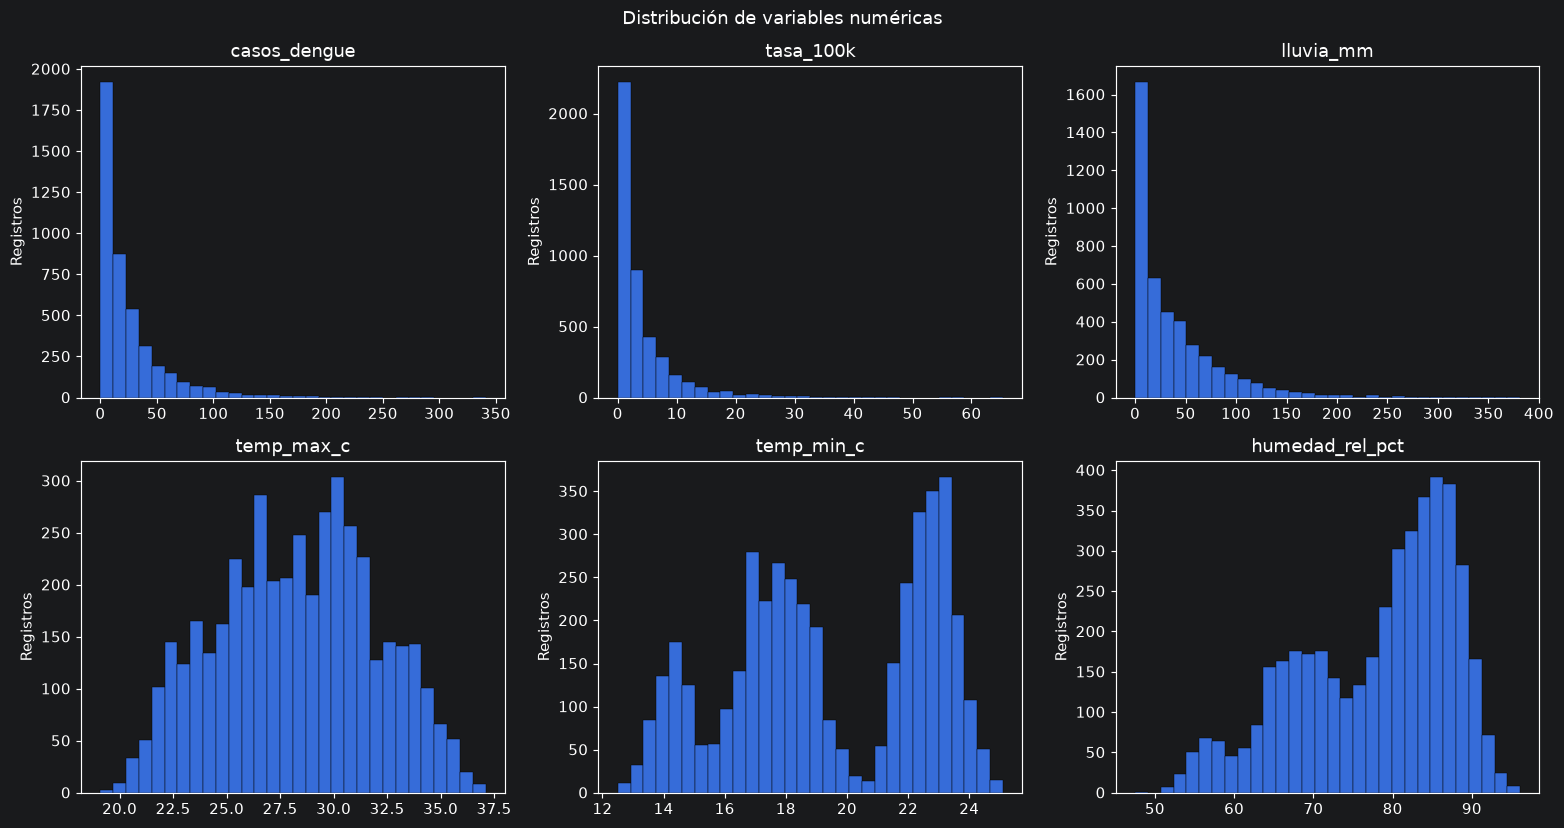

In [9]:
variables_dist = ["casos_dengue", "tasa_100k", "lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), variables_dist):
    ax.hist(datos[col].dropna(), bins=30, edgecolor="black", linewidth=0.3)
    ax.set_title(col)
    ax.set_ylabel("Registros")
plt.suptitle("Distribución de variables numéricas")
plt.tight_layout()
plt.show()

## 10. Detección de valores atípicos (IQR)

Se calculan posibles valores atípicos mediante el rango intercuartílico. En epidemias, los valores elevados pueden ser eventos relevantes y no errores.

,Variable,Límite inferior,Límite superior,Candidatos IQR
0,casos_dengue,-37.00,75.00,318
1,tasa_100k,-5.58,11.34,354
2,lluvia_mm,-70.35,131.65,211
3,temp_max_c,17.40,39.00,0
4,temp_min_c,8.60,31.00,0
5,humedad_rel_pct,47.45,108.65,0


C:\Users\andre\AppData\Local\Temp\ipykernel_17796\851255161.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(datos[col].dropna(), vert=True)
C:\Users\andre\AppData\Local\Temp\ipykernel_17796\851255161.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(datos[col].dropna(), vert=True)
C:\Users\andre\AppData\Local\Temp\ipykernel_17796\851255161.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(datos[col].dropna(), vert=True)
C:\Users\andre\AppData\Local\Temp\ipykernel_17796\851255161.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'ver

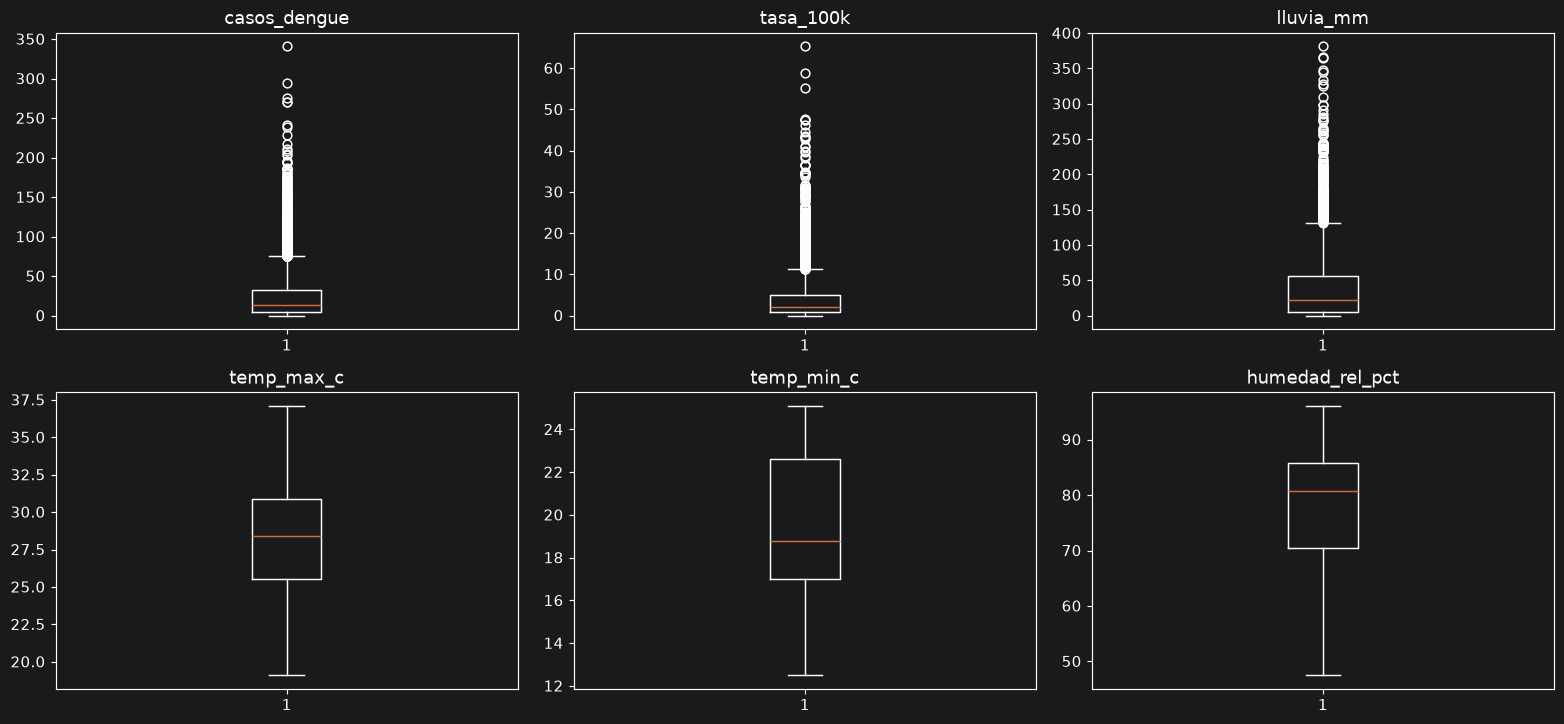

In [10]:
atipicos = []
for col in variables_dist:
    serie = datos[col].dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    atipicos.append({"Variable": col, "Límite inferior": inferior,
                     "Límite superior": superior, "Candidatos IQR": int(((serie < inferior) | (serie > superior)).sum())})
df_atipicos = pd.DataFrame(atipicos)
display(df_atipicos.round(2))
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), variables_dist):
    ax.boxplot(datos[col].dropna(), vert=True)
    ax.set_title(col)
plt.tight_layout(); plt.show()

## 11. Validación de rangos y consistencia

Se comprueban valores imposibles y se contrasta la tasa por 100.000 habitantes con los casos y la población aproximada.

In [11]:
validacion = pd.DataFrame([
    ("Casos negativos", int((datos["casos_dengue"] < 0).sum())),
    ("Población no positiva", int((datos["poblacion"] <= 0).sum())),
    ("Tasas negativas", int((datos["tasa_100k"] < 0).sum())),
    ("Lluvia negativa", int((datos["lluvia_mm"] < 0).sum())),
    ("Humedad fuera de [0, 100]", int(((datos["humedad_rel_pct"] < 0) | (datos["humedad_rel_pct"] > 100)).sum())),
    ("Temperatura mínima > máxima", int((datos["temp_min_c"] > datos["temp_max_c"]).sum()))
], columns=["Verificación", "Registros"])
display(validacion)
tasa_calculada = datos["casos_dengue"] / datos["poblacion"].replace(0, np.nan) * 100000
error_tasa = (tasa_calculada - datos["tasa_100k"]).abs()
print("Error absoluto máximo en tasa_100k (por redondeo):", round(error_tasa.max(), 5))
print("Registros con diferencia > 0.01:", int((error_tasa > 0.01).sum()))

,Verificación,Registros
0,Casos negativos,0
1,Población no positiva,0
2,Tasas negativas,0
3,Lluvia negativa,0
4,"Humedad fuera de [0, 100]",0
5,Temperatura mínima > máxima,0


Error absoluto máximo en tasa_100k (por redondeo): 0.00494
Registros con diferencia > 0.01: 0


## 12. Visualización exploratoria general

Se muestra la composición total de casos por provincia para dar contexto a las comparaciones posteriores.

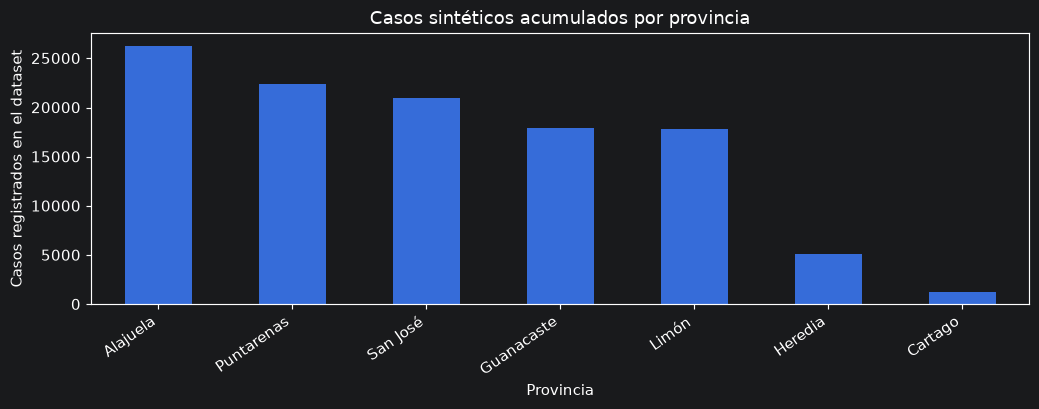

,Casos acumulados
provincia,
Alajuela,26290
Puntarenas,22436
San José,20943
Guanacaste,17891
Limón,17784
Heredia,5139
Cartago,1277


In [12]:
casos_provincia = datos.groupby("provincia")["casos_dengue"].sum().sort_values(ascending=False)
ax = casos_provincia.plot(kind="bar", figsize=(10, 4), title="Casos sintéticos acumulados por provincia")
ax.set_xlabel("Provincia")
ax.set_ylabel("Casos registrados en el dataset")
plt.xticks(rotation=35, ha="right")
plt.tight_layout(); plt.show()
display(casos_provincia.rename("Casos acumulados").to_frame())

## 13. Alcance y naturaleza de los datos

Se deja constancia de la procedencia sintética y la cobertura observada del archivo, sin interpretarlo como vigilancia epidemiológica real.

In [13]:
print("Naturaleza del archivo: SINTÉTICO (según LEEME_datos.md del profesor)")
print("Fecha inicial:", datos["fecha_inicio_semana"].min().date())
print("Fecha final:", datos["fecha_inicio_semana"].max().date())
print("Años:", sorted(datos["anio"].unique().tolist()))
print("Provincias:", sorted(datos["provincia"].unique().tolist()))
print("Variable objetivo: casos_dengue")

Naturaleza del archivo: SINTÉTICO (según LEEME_datos.md del profesor)
Fecha inicial: 2014-01-05
Fecha final: 2025-12-28
Años: [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Provincias: ['Alajuela', 'Cartago', 'Guanacaste', 'Heredia', 'Limón', 'Puntarenas', 'San José']
Variable objetivo: casos_dengue


## 14. Cobertura de las siete provincias

Se verifica que todas las provincias estén representadas y se cuentan las observaciones por cada una.

In [14]:
cobertura_provincias = datos.groupby("provincia").agg(
    Registros=("casos_dengue", "size"),
    Primera_semana=("fecha_inicio_semana", "min"),
    Última_semana=("fecha_inicio_semana", "max")
)
display(cobertura_provincias)
print("Provincias encontradas:", datos["provincia"].nunique())

,Registros,Primera_semana,Última_semana
provincia,,,
Alajuela,626,2014-01-05,2025-12-28
Cartago,626,2014-01-05,2025-12-28
Guanacaste,626,2014-01-05,2025-12-28
Heredia,626,2014-01-05,2025-12-28
Limón,626,2014-01-05,2025-12-28
Puntarenas,626,2014-01-05,2025-12-28
San José,626,2014-01-05,2025-12-28


Provincias encontradas: 7


## 15. Validación de fechas y semanas epidemiológicas

Se revisa que las fechas sean domingos, que cada provincia tenga periodicidad semanal y que las etiquetas epidemiológicas estén dentro de su rango permitido. La semana epidemiológica puede diferir del calendario ISO en cambios de año.

In [15]:
print("Fechas que no caen domingo:", int((datos["fecha_inicio_semana"].dt.dayofweek != 6).sum()))
print("Semanas epidemiológicas fuera de 1–53:", int((~datos["semana_epi"].between(1, 53)).sum()))
print("Año distinto del año calendario:", int((datos["anio"] != datos["fecha_inicio_semana"].dt.year).sum()))
saltos = datos.groupby("provincia")["fecha_inicio_semana"].diff().dt.days
print("Intervalos diferentes a 7 días:", int((saltos.dropna() != 7).sum()))
print("Frecuencia de intervalos:")
display(saltos.value_counts(dropna=True).rename("Intervalos").to_frame())

Fechas que no caen domingo: 0
Semanas epidemiológicas fuera de 1–53: 0
Año distinto del año calendario: 0
Intervalos diferentes a 7 días: 0
Frecuencia de intervalos:


C:\Users\andre\AppData\Local\Temp\ipykernel_17796\3399628023.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  print("Fechas que no caen domingo:", int((datos["fecha_inicio_semana"].dt.dayofweek != 6).sum()))


,Intervalos
fecha_inicio_semana,
7.0,4375


## 16. Cobertura por año y provincia

Se verifican los registros anuales y las semanas observadas en cada provincia. Algunos años pueden incluir 53 domingos.

In [16]:
tabla_cobertura = pd.crosstab(datos["anio"], datos["provincia"])
display(tabla_cobertura)
print("Semanas únicas por año:")
display(datos.groupby("anio")["fecha_inicio_semana"].nunique().rename("Semanas distintas").to_frame())

provincia,Alajuela,Cartago,Guanacaste,Heredia,Limón,Puntarenas,San José
anio,,,,,,,
2014,52,52,52,52,52,52,52
2015,52,52,52,52,52,52,52
2016,52,52,52,52,52,52,52
2017,53,53,53,53,53,53,53
2018,52,52,52,52,52,52,52
2019,52,52,52,52,52,52,52
2020,52,52,52,52,52,52,52
2021,52,52,52,52,52,52,52
2022,52,52,52,52,52,52,52


Semanas únicas por año:


,Semanas distintas
anio,
2014,52
2015,52
2016,52
2017,53
2018,52
2019,52
2020,52
2021,52
2022,52


## 17. Distribución de casos por provincia

Se comparan los totales semanales por provincia e identifican diferencias en tamaño y dispersión.

,count,sum,mean,median,max,std
provincia,,,,,,
Alajuela,626,26290,42.00,29.0,341,40.90
Cartago,626,1277,2.04,1.0,13,2.22
Guanacaste,626,17891,28.58,15.0,229,34.83
Heredia,626,5139,8.21,6.0,62,8.33
Limón,626,17784,28.41,20.0,294,28.24
Puntarenas,626,22436,35.84,26.5,276,32.83
San José,626,20943,33.46,22.0,241,34.76


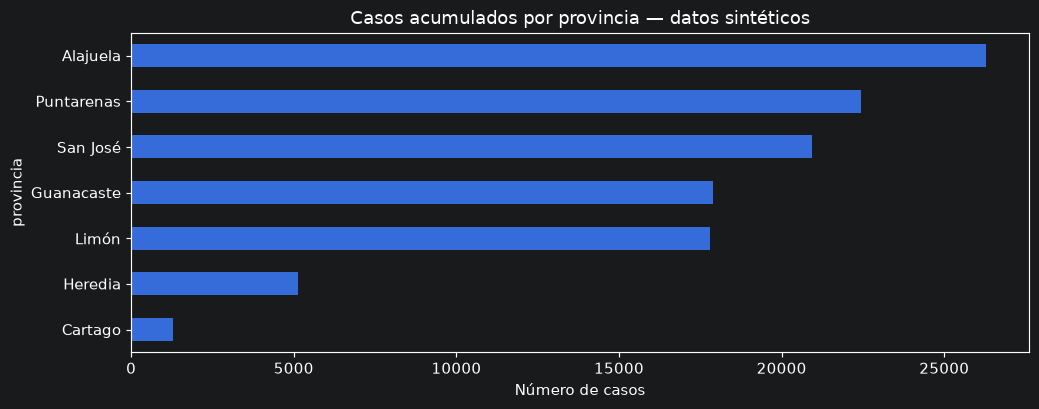

In [17]:
resumen_casos_prov = datos.groupby("provincia")["casos_dengue"].agg(["count", "sum", "mean", "median", "max", "std"])
display(resumen_casos_prov.round(2))
fig, ax = plt.subplots(figsize=(10, 4))
resumen_casos_prov["sum"].sort_values().plot(kind="barh", ax=ax)
ax.set_title("Casos acumulados por provincia — datos sintéticos")
ax.set_xlabel("Número de casos")
plt.tight_layout(); plt.show()

## 18. Evolución semanal de casos por provincia

Se visualizan las siete series provinciales para comparar sus tendencias y picos temporales.

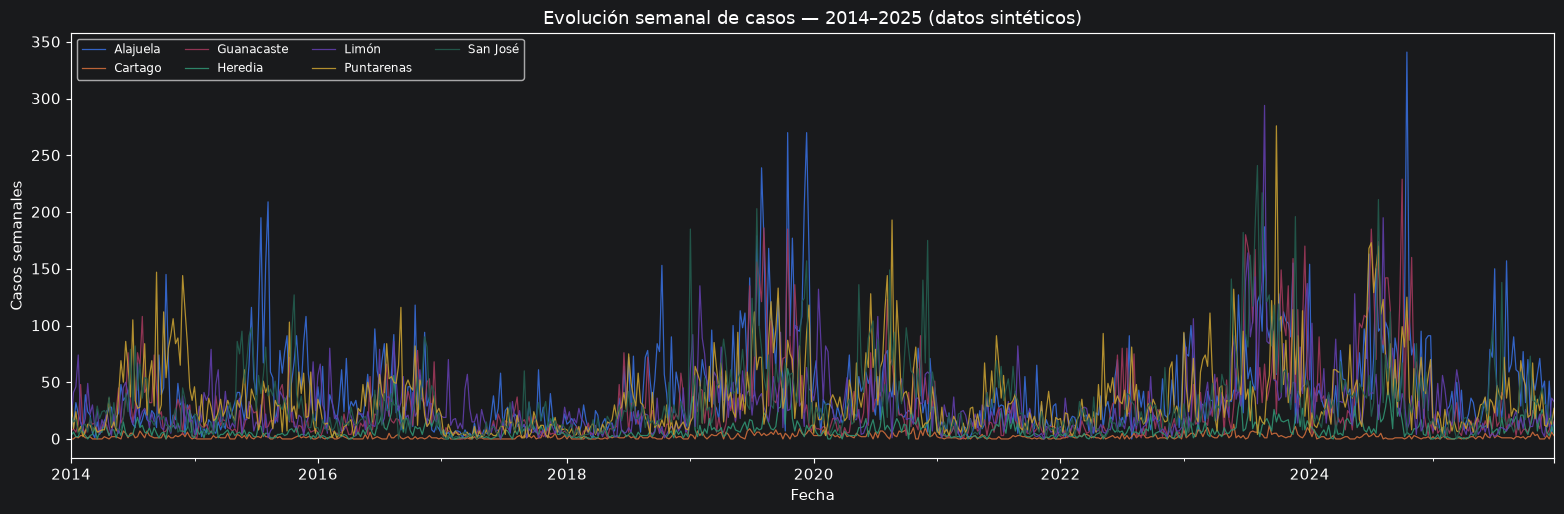

In [18]:
serie_casos = datos.pivot(index="fecha_inicio_semana", columns="provincia", values="casos_dengue")
ax = serie_casos.plot(figsize=(15, 5), linewidth=0.85, alpha=0.9)
ax.set_title("Evolución semanal de casos — 2014–2025 (datos sintéticos)")
ax.set_ylabel("Casos semanales")
ax.set_xlabel("Fecha")
plt.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

## 19. Comparación anual de casos entre provincias

Se agrupan los casos sintéticos de cada año para comparar los cambios temporales.

provincia,Alajuela,Cartago,Guanacaste,Heredia,Limón,Puntarenas,San José
anio,,,,,,,
2014,1397,110,1303,360,1093,2398,1195
2015,2556,65,896,256,1229,1551,1905
2016,2014,60,1151,528,1451,1645,1211
2017,731,53,492,256,769,430,578
2018,1696,54,878,200,633,915,866
2019,4550,201,2849,732,2386,2901,3145
2020,1946,208,1534,498,1997,2440,2653
2021,953,50,533,262,916,1186,1067
2022,1240,92,889,267,703,1478,947


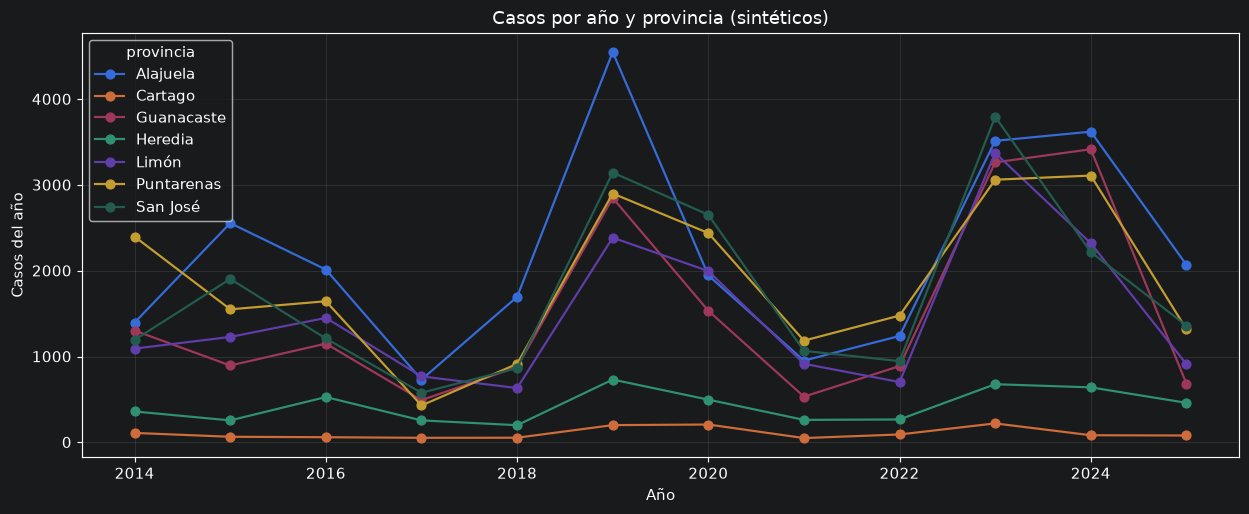

In [19]:
casos_anuales_prov = datos.pivot_table(index="anio", columns="provincia", values="casos_dengue", aggfunc="sum")
display(casos_anuales_prov)
casos_anuales_prov.plot(figsize=(12, 5), marker="o")
plt.title("Casos por año y provincia (sintéticos)")
plt.xlabel("Año")
plt.ylabel("Casos del año")
plt.grid(alpha=0.2)
plt.tight_layout(); plt.show()

## 20. Tasas de casos por 100.000 habitantes

Se comparan las tasas para disminuir la influencia del tamaño poblacional. Se muestra la tasa semanal promedio, no una tasa anual acumulada.

,mean,median,max
provincia,,,
Guanacaste,7.33,3.85,58.72
Puntarenas,7.17,5.30,55.20
Limón,6.31,4.44,65.33
Alajuela,3.82,2.64,31.00
San José,2.01,1.33,14.52
Heredia,1.58,1.15,11.92
Cartago,0.37,0.18,2.36


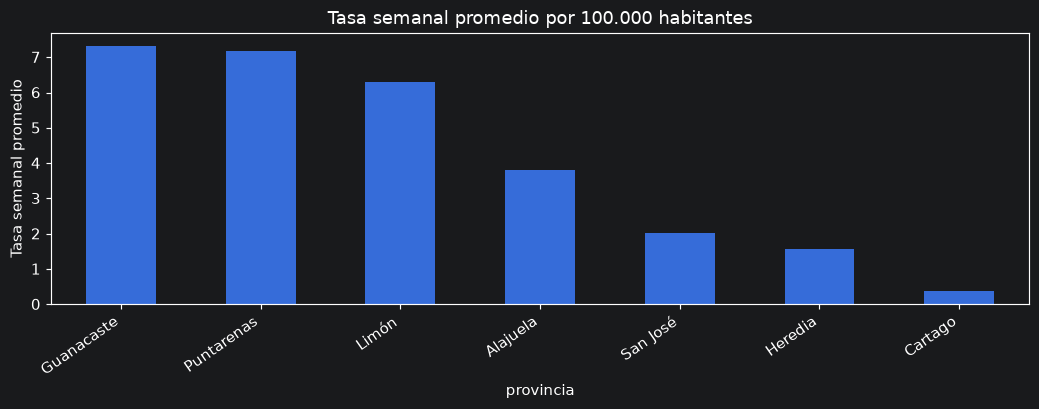

In [20]:
tasas_prov = datos.groupby("provincia")["tasa_100k"].agg(["mean", "median", "max"]).sort_values("mean", ascending=False)
display(tasas_prov.round(2))
ax = tasas_prov["mean"].plot(kind="bar", figsize=(10, 4), title="Tasa semanal promedio por 100.000 habitantes")
ax.set_ylabel("Tasa semanal promedio")
plt.xticks(rotation=35, ha="right")
plt.tight_layout(); plt.show()

## 21. Análisis de estacionalidad por provincia

Se calcula el promedio de casos por número de semana epidemiológica para identificar patrones estacionales. Los promedios son descriptivos de datos sintéticos.

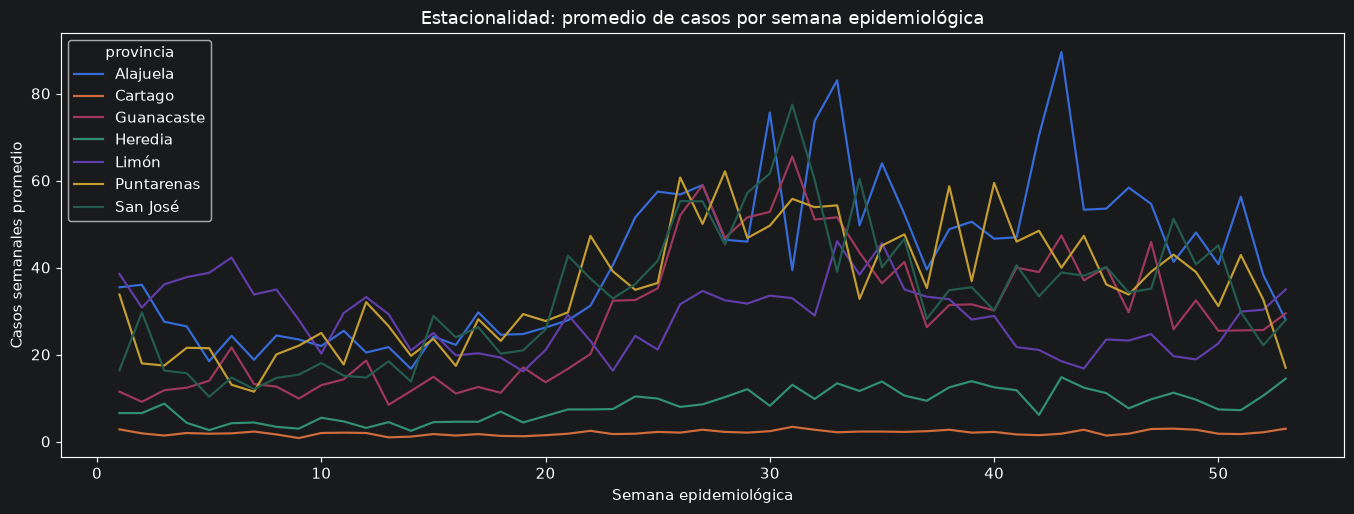

,Semana de mayor promedio
provincia,
Alajuela,43
Cartago,31
Guanacaste,31
Heredia,43
Limón,33
Puntarenas,28
San José,31


In [21]:
estacionalidad = datos.groupby(["semana_epi", "provincia"])["casos_dengue"].mean().unstack("provincia")
estacionalidad.plot(figsize=(13, 5), linewidth=1.5)
plt.title("Estacionalidad: promedio de casos por semana epidemiológica")
plt.xlabel("Semana epidemiológica")
plt.ylabel("Casos semanales promedio")
plt.tight_layout(); plt.show()
picos_estacionales = estacionalidad.idxmax().rename("Semana de mayor promedio").to_frame()
display(picos_estacionales)

## 22. Comparación de regiones climáticas

Se observa la correspondencia provincia-región. El número de provincias por región es desigual; las comparaciones posteriores deben considerar esa diferencia.

In [22]:
relacion_regiones = (datos[["provincia", "region_climatica"]]
                    .drop_duplicates().sort_values(["region_climatica", "provincia"]))
display(relacion_regiones)
print("Provincias distintas por región:")
display(relacion_regiones.groupby("region_climatica").size().rename("Provincias").to_frame())

,provincia,region_climatica
2504,Limón,Caribe
3130,Puntarenas,Pacífico Central/Sur
1252,Guanacaste,Pacífico Norte
0,Alajuela,Valle Central
626,Cartago,Valle Central
1878,Heredia,Valle Central
3756,San José,Valle Central


Provincias distintas por región:


,Provincias
region_climatica,
Caribe,1
Pacífico Central/Sur,1
Pacífico Norte,1
Valle Central,4


## 23. Patrones de precipitación en las regiones climáticas

Se compara la lluvia semanal promedio por semana epidemiológica para explorar las diferencias entre los regímenes climáticos regionales.

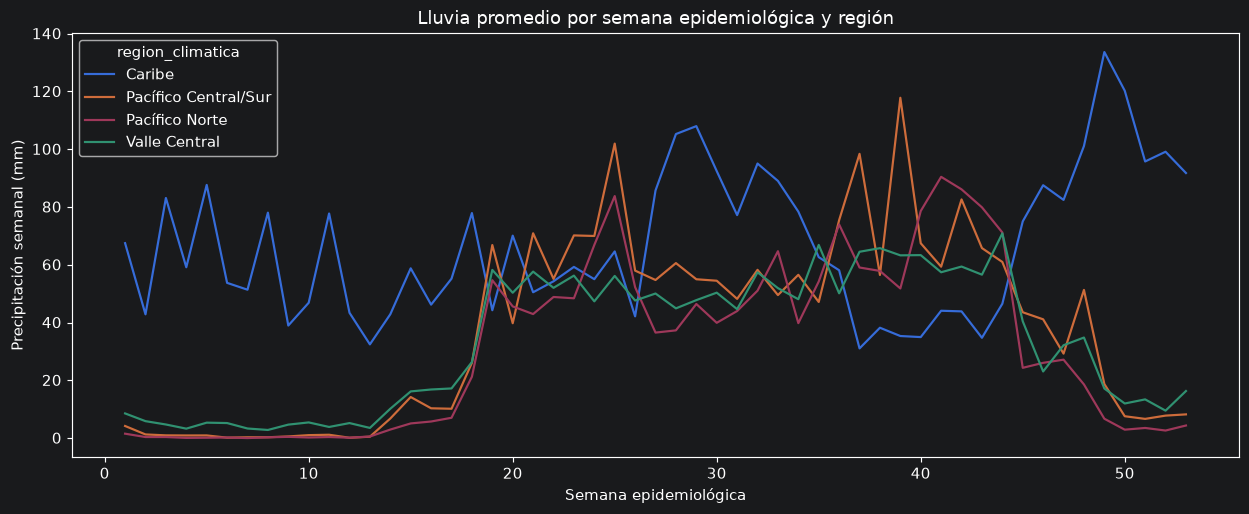

In [23]:
lluvia_regional = (datos.groupby(["region_climatica", "semana_epi"])["lluvia_mm"]
                  .mean().unstack("region_climatica"))
lluvia_regional.plot(figsize=(12, 5))
plt.title("Lluvia promedio por semana epidemiológica y región")
plt.xlabel("Semana epidemiológica")
plt.ylabel("Precipitación semanal (mm)")
plt.tight_layout(); plt.show()

## 24. Distribución de lluvia, temperaturas y humedad por provincia

Se analizan las variaciones climáticas con diagramas de caja para cada provincia.

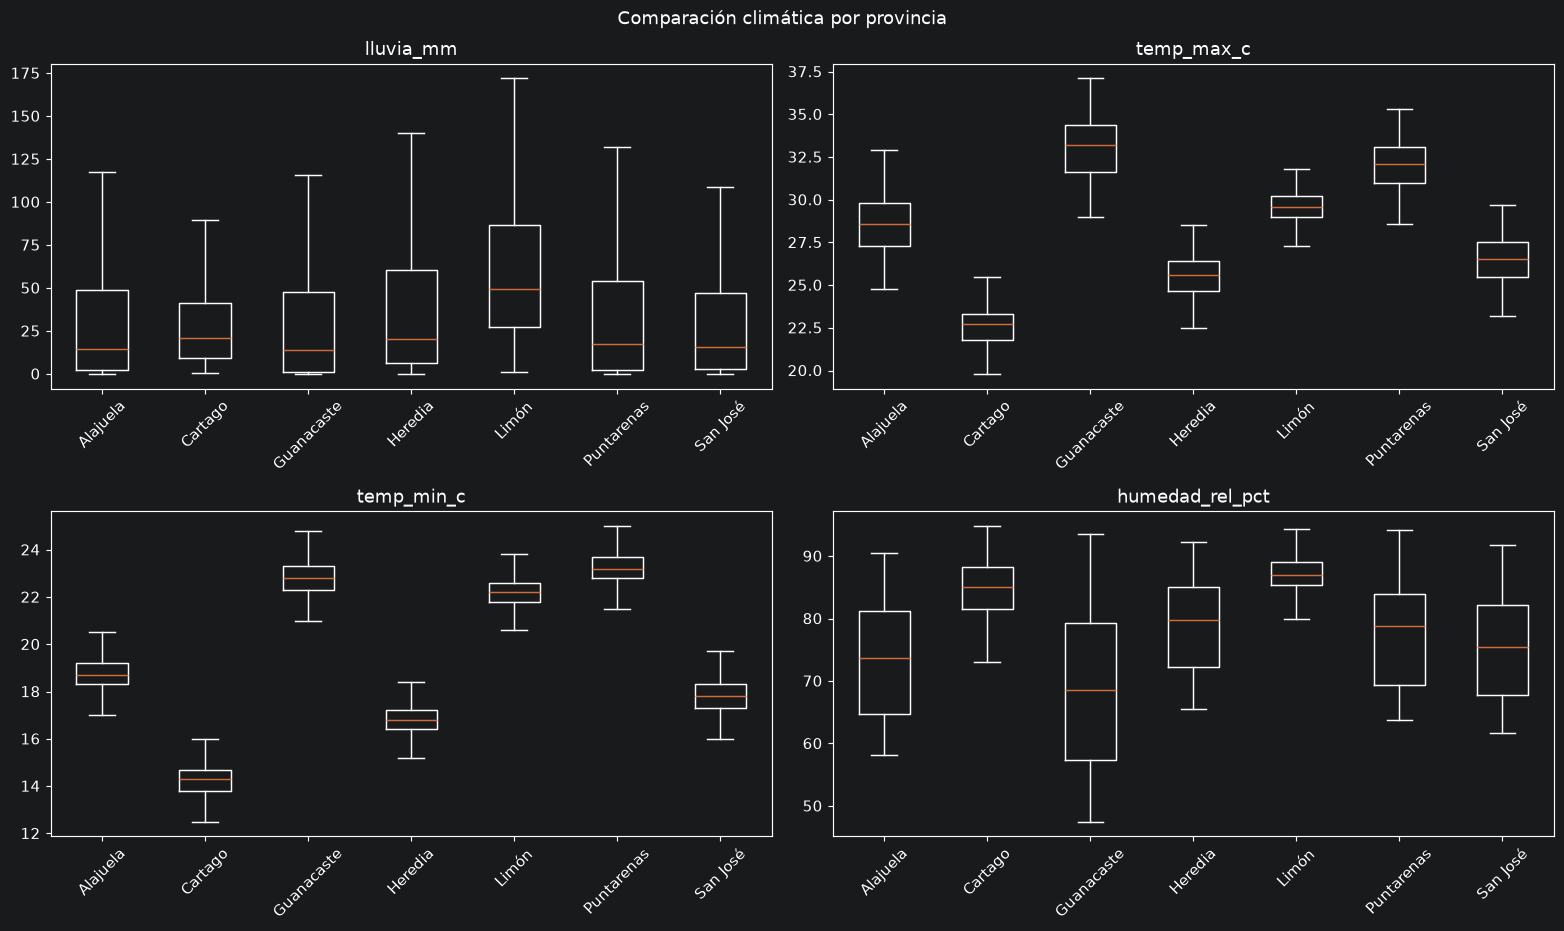

In [24]:
clima_cols = ["lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.ravel(), clima_cols):
    grupos = [datos.loc[datos["provincia"] == provincia, col].dropna()
              for provincia in sorted(datos["provincia"].unique())]
    ax.boxplot(grupos, tick_labels=sorted(datos["provincia"].unique()), showfliers=False)
    ax.set_title(col)
    ax.tick_params(axis="x", labelrotation=45)
plt.suptitle("Comparación climática por provincia")
plt.tight_layout(); plt.show()

## 25. Patrones de valores faltantes por provincia y año

Se localizan los nulos climáticos por provincia y por año para evaluar si se distribuyen de manera uniforme.

,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
provincia,,,,
Alajuela,5,6,0,2
Cartago,8,10,0,3
Guanacaste,5,5,0,4
Heredia,7,3,0,3
Limón,5,4,0,8
Puntarenas,5,2,0,6
San José,0,4,0,3


,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
anio,,,,
2014,4,1,0,5
2015,4,5,0,2
2016,2,3,0,2
2017,1,4,0,2
2018,3,2,0,1
2019,1,0,0,3
2020,2,2,0,4
2021,4,3,0,2
2022,2,3,0,2


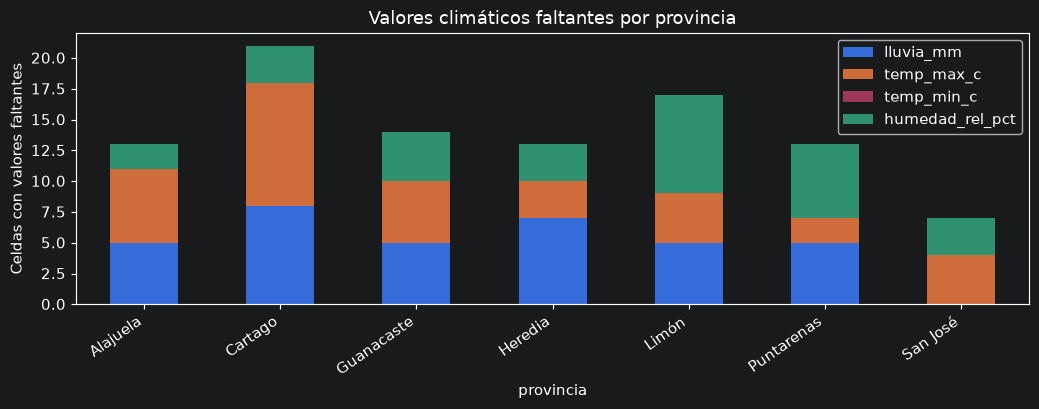

In [25]:
faltantes_clima_prov = datos.groupby("provincia")[clima_cols].apply(lambda grupo: grupo.isna().sum())
display(faltantes_clima_prov)
faltantes_anuales = datos.groupby("anio")[clima_cols].apply(lambda grupo: grupo.isna().sum())
display(faltantes_anuales)
fig, ax = plt.subplots(figsize=(10, 4))
faltantes_clima_prov.plot(kind="bar", stacked=True, ax=ax)
ax.set_ylabel("Celdas con valores faltantes")
ax.set_title("Valores climáticos faltantes por provincia")
plt.xticks(rotation=35, ha="right")
plt.tight_layout(); plt.show()

## 26. Evaluación exploratoria de estrategias de imputación

Se comparan los faltantes originales con una copia interpolada **solo para inspección**. No se reemplazan datos del CSV; en un entrenamiento real habría que evitar usar información futura para imputar.

In [26]:
datos_interpolados = datos.copy()
for variable in clima_cols:
    datos_interpolados[variable] = datos_interpolados.groupby("provincia")[variable].transform(
        lambda serie: serie.interpolate(method="linear", limit_direction="both")
    )
comparacion_imputacion = pd.DataFrame({
    "Faltantes originales": datos[clima_cols].isna().sum(),
    "Faltantes copia interpolada": datos_interpolados[clima_cols].isna().sum(),
    "Media original": datos[clima_cols].mean(),
    "Media copia interpolada": datos_interpolados[clima_cols].mean()
})
display(comparacion_imputacion.round(2))
print("Aviso: la interpolación puede usar semanas posteriores y NO debe trasladarse sin ajustes al entrenamiento.")

,Faltantes originales,Faltantes copia interpolada,Media original,Media copia interpolada
lluvia_mm,35,0,38.80,38.84
temp_max_c,34,0,28.27,28.26
temp_min_c,0,0,19.41,19.41
humedad_rel_pct,29,0,77.95,77.95


Aviso: la interpolación puede usar semanas posteriores y NO debe trasladarse sin ajustes al entrenamiento.


## 27. Matriz de correlaciones numéricas

Se comparan las relaciones lineales de las variables. Estas correlaciones descriptivas no implican causalidad ni por sí solas miden capacidad de predicción.

,casos_dengue,tasa_100k,poblacion,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
casos_dengue,1.000,0.842,0.174,0.083,0.235,0.267,0.027
tasa_100k,0.842,1.000,-0.186,0.122,0.381,0.441,0.063
poblacion,0.174,-0.186,1.000,-0.086,-0.255,-0.313,-0.173
lluvia_mm,0.083,0.122,-0.086,1.000,-0.093,0.113,0.573
temp_max_c,0.235,0.381,-0.255,-0.093,1.000,0.917,-0.417
temp_min_c,0.267,0.441,-0.313,0.113,0.917,1.000,-0.193
humedad_rel_pct,0.027,0.063,-0.173,0.573,-0.417,-0.193,1.000


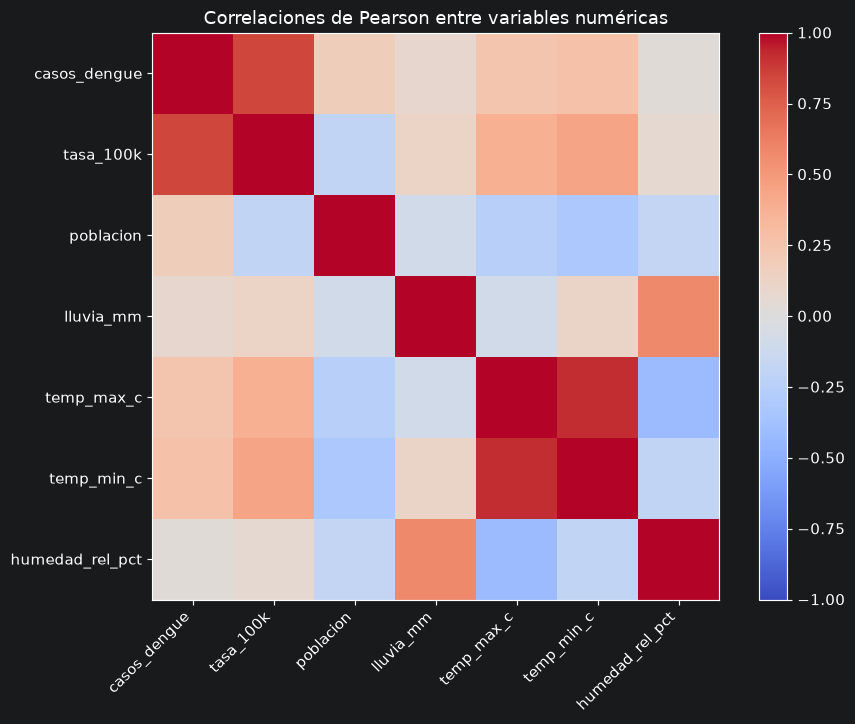

In [27]:
corr_vars = ["casos_dengue", "tasa_100k", "poblacion", *clima_cols]
matriz_corr = datos[corr_vars].corr()
display(matriz_corr.round(3))
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(matriz_corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_vars)), corr_vars, rotation=45, ha="right")
ax.set_yticks(range(len(corr_vars)), corr_vars)
fig.colorbar(im, ax=ax)
plt.title("Correlaciones de Pearson entre variables numéricas")
plt.tight_layout(); plt.show()

## 28. Relación entre clima y casos por provincia

Se calculan correlaciones contemporáneas de cada variable climática con log(1 + casos) para reducir el impacto de los picos.

Clima,humedad_rel_pct,lluvia_mm,temp_max_c,temp_min_c
Provincia,,,,
Alajuela,0.329,0.137,-0.167,-0.042
Cartago,0.091,0.043,-0.047,-0.013
Guanacaste,0.334,0.245,-0.189,-0.031
Heredia,0.301,0.160,-0.231,-0.097
Limón,0.049,0.058,0.085,0.134
Puntarenas,0.298,0.125,-0.112,-0.101
San José,0.277,0.098,-0.141,-0.050


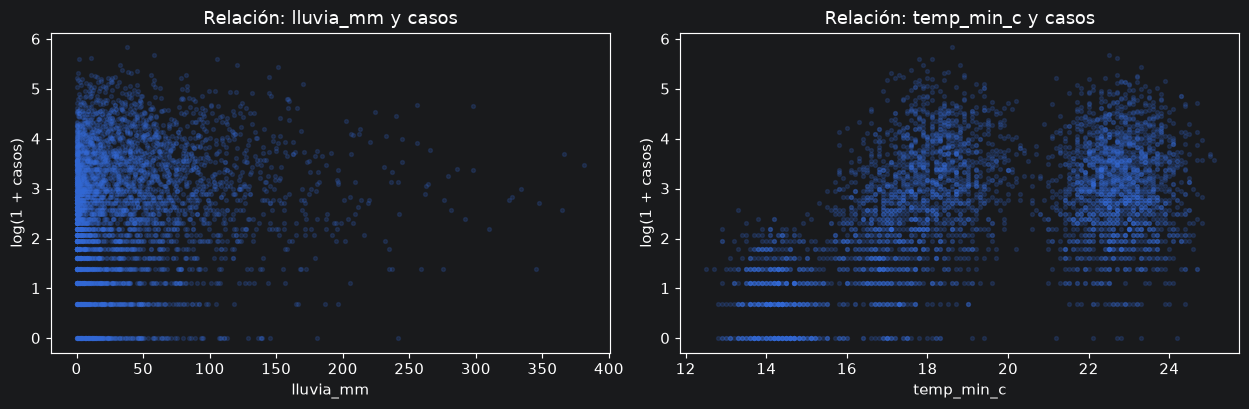

In [28]:
correlaciones_prov = []
for provincia, grupo in datos.groupby("provincia"):
    for col in clima_cols:
        correlaciones_prov.append({
            "Provincia": provincia, "Clima": col,
            "Correlación con log1p(casos)": grupo[col].corr(np.log1p(grupo["casos_dengue"]))
        })
df_corr_prov = pd.DataFrame(correlaciones_prov)
display(df_corr_prov.pivot(index="Provincia", columns="Clima", values="Correlación con log1p(casos)").round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["lluvia_mm", "temp_min_c"]):
    muestra = datos[[col, "casos_dengue"]].dropna()
    ax.scatter(muestra[col], np.log1p(muestra["casos_dengue"]), s=7, alpha=0.18)
    ax.set(xlabel=col, ylabel="log(1 + casos)", title=f"Relación: {col} y casos")
plt.tight_layout(); plt.show()

## 29. Análisis de rezagos climáticos de 0 a 12 semanas

Se analizan las asociaciones entre clima **anterior** y casos posteriores, calculando los rezagos dentro de cada provincia y evitando mezclar semanas entre provincias.

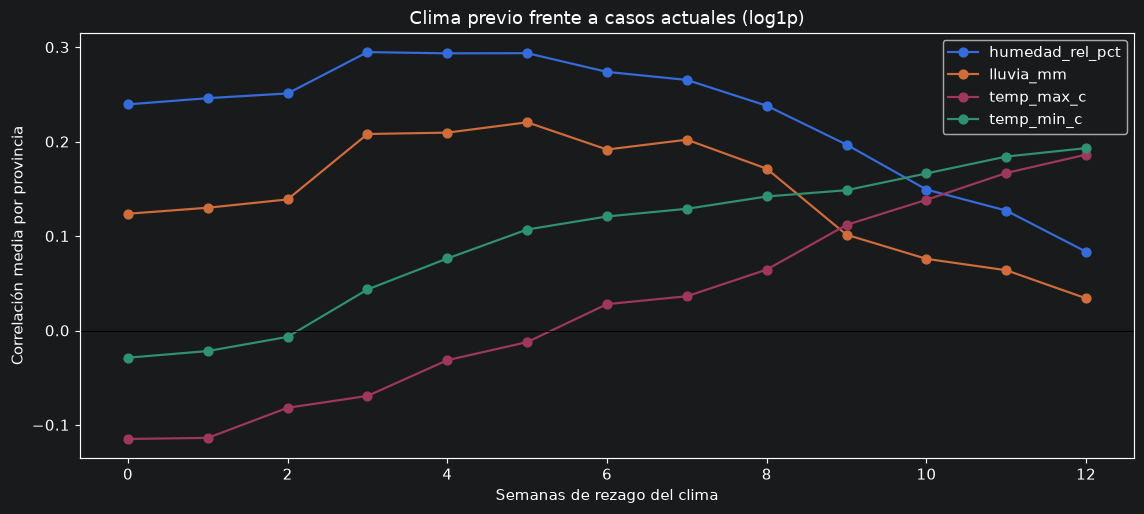

In [29]:
lag_results = []
for provincia, grupo in datos.groupby("provincia", sort=False):
    objetivo = np.log1p(grupo["casos_dengue"])
    for variable in clima_cols:
        for rezago in range(13):
            correlacion = grupo[variable].shift(rezago).corr(objetivo)
            lag_results.append({"Provincia": provincia, "Variable": variable,
                                "Rezago": rezago, "Correlación": correlacion})
df_rezagos = pd.DataFrame(lag_results)
resumen_lags = df_rezagos.groupby(["Variable", "Rezago"], as_index=False)["Correlación"].mean()
resumen_lags = resumen_lags.rename(columns={"Correlación": "Correlación media provincial"})
fig, ax = plt.subplots(figsize=(11, 5))
for variable, grupo in resumen_lags.groupby("Variable"):
    ax.plot(grupo["Rezago"], grupo["Correlación media provincial"], marker="o", label=variable)
ax.axhline(0, color="black", linewidth=0.7)
ax.set(xlabel="Semanas de rezago del clima", ylabel="Correlación media por provincia",
       title="Clima previo frente a casos actuales (log1p)")
ax.legend()
plt.tight_layout(); plt.show()

## 30. Rezagos más destacados por provincia

Se muestran, para cada provincia y variable climática, las semanas con mayor correlación absoluta. Los rezagos más altos deben validarse temporalmente antes de usarlos como predictores.

In [30]:
mejores_rezagos = (df_rezagos.assign(abs_r=lambda t: t["Correlación"].abs())
                  .sort_values("abs_r", ascending=False)
                  .drop_duplicates(["Provincia", "Variable"])
                  .sort_values(["Provincia", "Variable"]))
display(mejores_rezagos[["Provincia", "Variable", "Rezago", "Correlación"]].round(3))
print("Mejores rezagos medios según correlación absoluta:")
display(resumen_lags.assign(abs_r=lambda t: t["Correlación media provincial"].abs())
        .sort_values("abs_r", ascending=False).drop_duplicates("Variable")
        [["Variable", "Rezago", "Correlación media provincial"]].round(3))

,Provincia,Variable,Rezago,Correlación
42,Alajuela,humedad_rel_pct,3,0.397
3,Alajuela,lluvia_mm,3,0.268
25,Alajuela,temp_max_c,12,0.254
38,Alajuela,temp_min_c,12,0.264
94,Cartago,humedad_rel_pct,3,0.132
56,Cartago,lluvia_mm,4,0.107
66,Cartago,temp_max_c,1,-0.053
80,Cartago,temp_min_c,2,-0.103
147,Guanacaste,humedad_rel_pct,4,0.394
108,Guanacaste,lluvia_mm,4,0.300


Mejores rezagos medios según correlación absoluta:


,Variable,Rezago,Correlación media provincial
3,humedad_rel_pct,3,0.295
18,lluvia_mm,5,0.221
51,temp_min_c,12,0.193
38,temp_max_c,12,0.186


## 31. Años con mayores y menores casos y semanas atípicas

Se identifican los años y las semanas con mayor y menor cantidad de casos dentro de este conjunto sintético.

In [31]:
anual_total = datos.groupby("anio")["casos_dengue"].sum().sort_values(ascending=False)
display(anual_total.rename("Casos totales sintéticos").to_frame())
picos_prov = (datos.sort_values("casos_dengue", ascending=False)
              .drop_duplicates("provincia")
              [["provincia", "fecha_inicio_semana", "casos_dengue", "lluvia_mm", "temp_max_c"]])
print("Semana con mayor cantidad de casos por provincia:")
display(picos_prov.sort_values("provincia"))
print("Año con mayor total:", int(anual_total.index[0]))
print("Año con menor total:", int(anual_total.index[-1]))

,Casos totales sintéticos
anio,
2023,17910
2019,16764
2024,15412
2020,11276
2015,8458
2016,8060
2014,7856
2025,6890
2022,5616


Semana con mayor cantidad de casos por provincia:


,provincia,fecha_inicio_semana,casos_dengue,lluvia_mm,temp_max_c
563,Alajuela,2024-10-20,341,37.7,27.1
1116,Cartago,2023-05-28,13,10.7,23.9
1813,Guanacaste,2024-10-06,229,151.5,29.9
2180,Heredia,2019-10-20,62,17.5,24.2
3007,Limón,2023-08-27,294,58.2,29.4
3638,Puntarenas,2023-10-01,276,10.6,31.9
4256,San José,2023-08-06,241,32.4,26.5


Año con mayor total: 2023
Año con menor total: 2017


## 32. Autocorrelación de casos semanales

Se comparan los valores semanales con los de semanas previas de la misma provincia, incluyendo rezagos cercanos a un año.

Rezago,1,2,4,8,12,26,52
Provincia,,,,,,,
Alajuela,0.516,0.469,0.397,0.365,0.259,0.046,0.132
Cartago,0.330,0.285,0.266,0.252,0.184,0.172,0.044
Guanacaste,0.642,0.624,0.542,0.316,0.283,-0.011,0.232
Heredia,0.475,0.397,0.341,0.157,0.107,-0.100,0.096
Limón,0.496,0.407,0.395,0.325,0.258,0.159,0.047
Puntarenas,0.528,0.539,0.397,0.267,0.179,0.001,0.121
San José,0.579,0.561,0.468,0.319,0.211,0.001,0.178


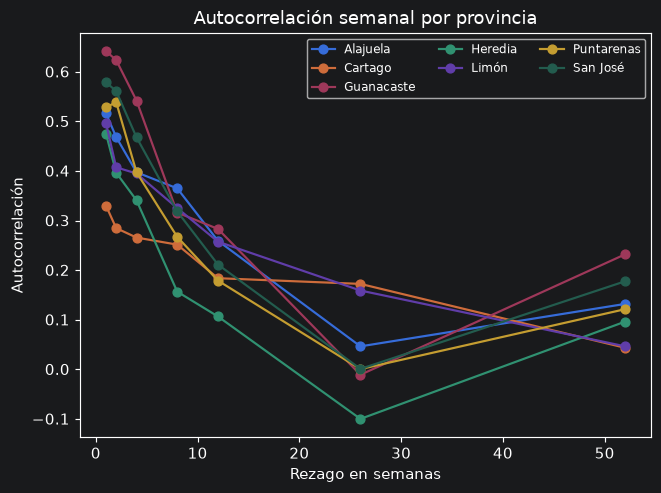

In [32]:
rezagos_autocorr = [1, 2, 4, 8, 12, 26, 52]
autocorr = []
for provincia, grupo in datos.groupby("provincia"):
    for lag in rezagos_autocorr:
        autocorr.append({"Provincia": provincia, "Rezago": lag,
                         "Autocorrelación": grupo["casos_dengue"].autocorr(lag=lag)})
df_autocorr = pd.DataFrame(autocorr)
display(df_autocorr.pivot(index="Provincia", columns="Rezago", values="Autocorrelación").round(3))
for prov, grupo in df_autocorr.groupby("Provincia"):
    plt.plot(grupo["Rezago"], grupo["Autocorrelación"], marker="o", label=prov)
plt.title("Autocorrelación semanal por provincia")
plt.xlabel("Rezago en semanas")
plt.ylabel("Autocorrelación")
plt.legend(fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

## 33. Baseline estacional: comparación con 52 semanas anteriores

Se calcula una predicción de referencia usando los casos de aproximadamente la misma semana del año anterior (rezago de 52 registros, por provincia). Es una aproximación en años con 53 semanas; se informa MAE y RMSE sin entrenar modelos.

In [33]:
datos_base = datos[["provincia", "fecha_inicio_semana", "anio", "casos_dengue"]].copy()
datos_base["baseline_52_semanas"] = datos_base.groupby("provincia")["casos_dengue"].shift(52)
evaluacion = datos_base.loc[(datos_base["anio"] >= 2024) & datos_base["baseline_52_semanas"].notna()].copy()
def metricas_baseline(grupo):
    error = grupo["casos_dengue"] - grupo["baseline_52_semanas"]
    return pd.Series({"Semanas evaluadas": len(grupo),
                      "MAE": error.abs().mean(),
                      "RMSE": np.sqrt(np.mean(error**2))})
metricas_prov = evaluacion.groupby("provincia").apply(metricas_baseline, include_groups=False)
display(metricas_prov.round(2))
print("Métricas globales de la referencia:")
display(metricas_baseline(evaluacion).round(2).to_frame("Valor"))

,Semanas evaluadas,MAE,RMSE
provincia,,,
Alajuela,104.0,40.08,59.57
Cartago,104.0,2.43,3.45
Guanacaste,104.0,46.59,64.82
Heredia,104.0,9.45,13.39
Limón,104.0,35.51,51.68
Puntarenas,104.0,44.33,59.41
San José,104.0,34.34,49.12


Métricas globales de la referencia:


,Valor
Semanas evaluadas,728.00
MAE,30.39
RMSE,48.63


## 34. Ventanas temporales de entrada de 12 a 30 semanas

Se comprueba cuántos ejemplos pueden construirse con 12, 26 o 30 semanas históricas y un horizonte de cuatro semanas **posteriores**. Solo se calcula la disponibilidad de ventanas; no se entrena ningún modelo.

In [34]:
ventanas = []
for tamaño_entrada in [12, 26, 30]:
    for provincia, grupo in datos.groupby("provincia"):
        n = len(grupo)
        ventanas.append({"Ventana histórica": tamaño_entrada,
                         "Provincia": provincia,
                         "Semanas disponibles": n,
                         "Ventanas teóricas (salida 4)": max(n - tamaño_entrada - 4 + 1, 0)})
df_ventanas = pd.DataFrame(ventanas)
display(df_ventanas.pivot(index="Provincia", columns="Ventana histórica", values="Ventanas teóricas (salida 4)"))
print("Ejemplo de objetivo futuro para una provincia:")
ejemplo = datos.loc[datos["provincia"] == sorted(datos["provincia"].unique())[0]].copy().reset_index(drop=True)
for i in range(1, 5):
    ejemplo[f"casos_t_mas_{i}"] = ejemplo["casos_dengue"].shift(-i)
display(ejemplo[["fecha_inicio_semana", "casos_dengue", "casos_t_mas_1", "casos_t_mas_2", "casos_t_mas_3", "casos_t_mas_4"]].iloc[25:31])

Ventana histórica,12,26,30
Provincia,,,
Alajuela,611,597,593
Cartago,611,597,593
Guanacaste,611,597,593
Heredia,611,597,593
Limón,611,597,593
Puntarenas,611,597,593
San José,611,597,593


Ejemplo de objetivo futuro para una provincia:


,fecha_inicio_semana,casos_dengue,casos_t_mas_1,casos_t_mas_2,casos_t_mas_3,casos_t_mas_4
25,2014-06-29,20,13.0,10.0,67.0,11.0
26,2014-07-06,13,10.0,67.0,11.0,17.0
27,2014-07-13,10,67.0,11.0,17.0,25.0
28,2014-07-20,67,11.0,17.0,25.0,17.0
29,2014-07-27,11,17.0,25.0,17.0,15.0
30,2014-08-03,17,25.0,17.0,15.0,25.0


## 35. Revisión de separación temporal y prevención de fugas

Se identifica un esquema posible de partición cronológica y se advierte sobre la imputación y el escalado con datos futuros. **Esta sección es orientativa; no genera ni entrena particiones de modelos.**

In [35]:
def etiqueta_periodo(anio):
    if anio <= 2021: return "Entrenamiento sugerido (2014–2021)"
    if anio <= 2023: return "Validación sugerida (2022–2023)"
    return "Prueba sugerida (2024–2025)"
datos_periodos = datos.assign(Periodo=datos["anio"].map(etiqueta_periodo))
display(datos_periodos.groupby("Periodo").agg(
    Filas=("casos_dengue", "size"),
    Semanas=("fecha_inicio_semana", "nunique"),
    Provincias=("provincia", "nunique")
))
print("Precauciones: escaladores e imputadores deben ajustarse solo con entrenamiento; las ventanas de entrada no deben incluir objetivos futuros.")

,Filas,Semanas,Provincias
Periodo,,,
Entrenamiento sugerido (2014–2021),2919,417,7
Prueba sugerida (2024–2025),728,104,7
Validación sugerida (2022–2023),735,105,7


Precauciones: escaladores e imputadores deben ajustarse solo con entrenamiento; las ventanas de entrada no deben incluir objetivos futuros.


## 36. Comparación de patrones entre regiones y provincias

Se contrasta la precipitación semanal promedio de Limón (Caribe) frente al conjunto de las demás provincias, sin atribuir causalidad ni tratar los registros sintéticos como oficiales.

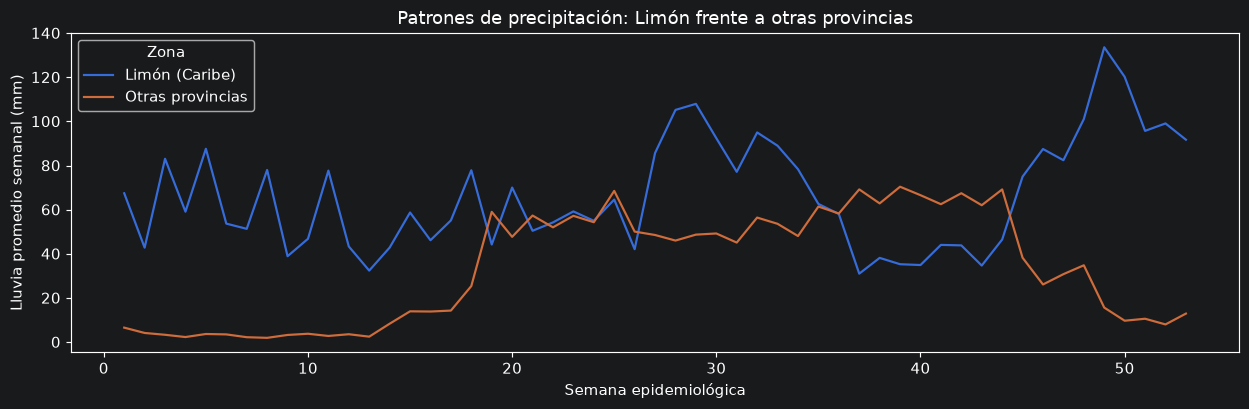

Promedios de lluvia por región:


,count,mean,median,max
region_climatica,,,,
Caribe,621,66.13,49.7,381.5
Pacífico Central/Sur,621,38.05,17.2,364.9
Pacífico Norte,621,31.73,13.7,298.2
Valle Central,2484,33.93,18.3,345.4


In [36]:
lluvia_comparativa = datos.assign(Zona=np.where(datos["provincia"].eq("Limón"), "Limón (Caribe)", "Otras provincias"))
perfil = lluvia_comparativa.groupby(["semana_epi", "Zona"])["lluvia_mm"].mean().unstack()
perfil.plot(figsize=(12, 4))
plt.title("Patrones de precipitación: Limón frente a otras provincias")
plt.xlabel("Semana epidemiológica")
plt.ylabel("Lluvia promedio semanal (mm)")
plt.tight_layout(); plt.show()
print("Promedios de lluvia por región:")
display(datos.groupby("region_climatica")["lluvia_mm"].agg(["count", "mean", "median", "max"]).round(2))

## 37. Resumen automático de resultados

Se consolidan las principales métricas observadas en el EDA. **El resumen no redacta conclusiones**, que quedan reservadas para el equipo.

In [37]:
print("=" * 70)
print("RESUMEN AUTOMÁTICO — EDA 09: DENGUE PROVINCIAL (DATOS SINTÉTICOS)")
print("=" * 70)
resumen = [
    ("Filas analizadas", len(datos)),
    ("Columnas originales", columnas),
    ("Provincias identificadas", datos["provincia"].nunique()),
    ("Regiones climáticas", datos["region_climatica"].nunique()),
    ("Semanas únicas en el período", datos["fecha_inicio_semana"].nunique()),
    ("Fecha inicial", str(datos["fecha_inicio_semana"].min().date())),
    ("Fecha final", str(datos["fecha_inicio_semana"].max().date())),
    ("Años distintos", datos["anio"].nunique()),
    ("Filas duplicadas exactas", duplicados_exactos),
    ("Provincia-fecha duplicadas", duplicados_clave),
    ("Celdas faltantes", int(datos.isna().sum().sum())),
    ("Registros con algún faltante", int(datos.isna().any(axis=1).sum())),
    ("Faltantes en lluvia", int(datos["lluvia_mm"].isna().sum())),
    ("Faltantes en temperatura máxima", int(datos["temp_max_c"].isna().sum())),
    ("Faltantes en temperatura mínima", int(datos["temp_min_c"].isna().sum())),
    ("Faltantes en humedad", int(datos["humedad_rel_pct"].isna().sum())),
    ("Saltos semanales distintos de 7 días", int((saltos.dropna() != 7).sum())),
    ("Casos totales del dataset (sintéticos)", int(datos["casos_dengue"].sum())),
    ("Casos máximos en una provincia-semana", int(datos["casos_dengue"].max())),
    ("Año con mayor total sintético", int(anual_total.idxmax())),
    ("Año con menor total sintético", int(anual_total.idxmin())),
    ("Provincia con mayor total sintético", casos_provincia.idxmax()),
    ("Provincia con menor total sintético", casos_provincia.idxmin()),
    ("Baseline 52 semanas: MAE global (2024–2025)", round(float(metricas_baseline(evaluacion)["MAE"]), 3)),
    ("Baseline 52 semanas: RMSE global (2024–2025)", round(float(metricas_baseline(evaluacion)["RMSE"]), 3))
]
resumen_eda = pd.DataFrame(resumen, columns=["Indicador", "Resultado"])
display(resumen_eda)
print("\nDistribución por provincia:")
display(datos.groupby("provincia")["casos_dengue"].agg(Registros="size", Casos="sum", Media="mean").round(2))
print("\nFaltantes climáticos por provincia:")
display(faltantes_clima_prov)
print("\nCorrelaciones de rezago más marcadas (media provincial):")
display(resumen_lags.assign(abs_r=lambda x: x["Correlación media provincial"].abs())
        .sort_values("abs_r", ascending=False).drop_duplicates("Variable")
        [["Variable", "Rezago", "Correlación media provincial"]].round(3))
print("\nLa interpretación y las conclusiones se redactarán después de revisar estos resultados.")

RESUMEN AUTOMÁTICO — EDA 09: DENGUE PROVINCIAL (DATOS SINTÉTICOS)


,Indicador,Resultado
0,Filas analizadas,4382
1,Columnas originales,12
2,Provincias identificadas,7
3,Regiones climáticas,4
4,Semanas únicas en el período,626
5,Fecha inicial,2014-01-05
6,Fecha final,2025-12-28
7,Años distintos,12
8,Filas duplicadas exactas,0
9,Provincia-fecha duplicadas,0



Distribución por provincia:


,Registros,Casos,Media
provincia,,,
Alajuela,626,26290,42.00
Cartago,626,1277,2.04
Guanacaste,626,17891,28.58
Heredia,626,5139,8.21
Limón,626,17784,28.41
Puntarenas,626,22436,35.84
San José,626,20943,33.46



Faltantes climáticos por provincia:


,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
provincia,,,,
Alajuela,5,6,0,2
Cartago,8,10,0,3
Guanacaste,5,5,0,4
Heredia,7,3,0,3
Limón,5,4,0,8
Puntarenas,5,2,0,6
San José,0,4,0,3



Correlaciones de rezago más marcadas (media provincial):


,Variable,Rezago,Correlación media provincial
3,humedad_rel_pct,3,0.295
18,lluvia_mm,5,0.221
51,temp_min_c,12,0.193
38,temp_max_c,12,0.186



La interpretación y las conclusiones se redactarán después de revisar estos resultados.



## 38. Conclusiones generales del EDA

El análisis exploratorio del dataset `vectoria_dengue_semanal.csv` permitió estudiar el comportamiento simulado de los casos de dengue en las siete provincias de Costa Rica durante el período 2014–2025.

Se examinaron las distribuciones de casos, las diferencias provinciales, las condiciones climáticas, los valores faltantes, la estacionalidad y las relaciones temporales entre el clima y los casos de dengue.

El objetivo fue identificar patrones y limitaciones relevantes para el desarrollo de un modelo adicional de predicción de casos de dengue por provincia dentro del proyecto VectorIA.

**Importante:** este dataset es sintético. Los casos y condiciones representados fueron generados para fines académicos, por lo que sus resultados no deben interpretarse como estadísticas epidemiológicas oficiales de Costa Rica.

### 38.1. Principales hallazgos

1. **Cantidad de registros:** se analizaron 4.382 registros distribuidos en 12 columnas originales, correspondientes a siete provincias y 626 semanas por provincia.

2. **Cobertura temporal:** el conjunto contiene información semanal desde el 5 de enero de 2014 hasta el 28 de diciembre de 2025, abarcando 12 años y cuatro regiones climáticas.

3. **Integridad temporal:** no se identificaron filas duplicadas, combinaciones repetidas de provincia y fecha, ni saltos semanales diferentes de siete días. Esto demuestra una estructura temporal consistente.

4. **Valores faltantes:** se encontraron 98 celdas sin información, distribuidas en 97 registros. Los faltantes corresponden a:
   - Lluvia: 35 valores.
   - Temperatura máxima: 34 valores.
   - Humedad relativa: 29 valores.
   - Temperatura mínima: 0 valores.

   Estas ausencias fueron introducidas intencionalmente para practicar técnicas de tratamiento de datos faltantes.

5. **Cantidad total de casos:** el dataset contiene 111.760 casos sintéticos acumulados durante el período analizado. Este valor corresponde exclusivamente a los datos simulados.

6. **Distribución provincial:** los casos acumulados presentan diferencias importantes entre provincias:

   - Alajuela: 26.290 casos.
   - Puntarenas: 22.436 casos.
   - San José: 20.943 casos.
   - Guanacaste: 17.891 casos.
   - Limón: 17.784 casos.
   - Heredia: 5.139 casos.
   - Cartago: 1.277 casos.

   Alajuela presenta el mayor acumulado, mientras que Cartago registra la menor cantidad dentro del conjunto sintético.

7. **Tasas de incidencia:** al comparar los casos por cada 100.000 habitantes, Guanacaste y Puntarenas presentan las mayores tasas semanales promedio, seguidas de Limón. Esto demuestra que la clasificación de provincias cambia al considerar la población y no únicamente la cantidad absoluta de casos.

8. **Distribución de casos semanales:** la variable `casos_dengue` presenta una distribución asimétrica hacia la derecha. Predominan los registros con pocos casos, mientras que algunas semanas presentan cantidades considerablemente superiores.

9. **Valores máximos:** el registro máximo fue de 341 casos en una provincia durante una semana. Los valores elevados deben revisarse como posibles períodos epidémicos simulados antes de considerarlos errores.

10. **Comportamiento anual:** el año 2023 presentó la mayor cantidad total de casos sintéticos, mientras que 2017 registró la menor. Esto refleja la presencia de años con distinta intensidad epidémica dentro de la simulación.

11. **Evolución temporal:** los gráficos muestran fluctuaciones semanales importantes entre 2014 y 2025. Se observan períodos de incremento y disminución de casos, con picos destacados durante los años de mayor actividad simulada.

12. **Estacionalidad:** se identificaron patrones asociados a determinadas semanas epidemiológicas. Varias provincias presentan incrementos de casos durante la segunda mitad del año, especialmente alrededor de las semanas 25 a 35, aunque el comportamiento no es idéntico en todas ellas.

13. **Diferencias climáticas provinciales:** se observaron variaciones importantes en lluvia, temperatura máxima, temperatura mínima y humedad relativa. Las provincias no presentan condiciones meteorológicas uniformes.

14. **Precipitación:** Limón presenta una distribución de lluvias diferente a la de varias provincias, con valores semanales generalmente superiores. Esto resulta relevante porque el régimen climático caribeño puede generar patrones temporales distintos.

15. **Temperatura:** Guanacaste y Puntarenas presentan temperaturas relativamente elevadas, mientras que Cartago registra valores inferiores. Estas diferencias justifican analizar las condiciones climáticas por provincia.

16. **Humedad relativa:** la distribución de humedad también presenta diferencias provinciales. Limón mantiene valores relativamente altos, mientras que otras provincias muestran mayor variabilidad.

17. **Correlaciones entre variables:** la matriz de Pearson permitió identificar asociaciones entre los casos de dengue, las tasas de incidencia, la población y las variables meteorológicas. Algunas relaciones pueden estar influenciadas por las diferencias estructurales entre provincias.

18. **Correlaciones climáticas con rezagos:** el análisis identificó las siguientes correlaciones máximas positivas aproximadas entre clima previo y log(1 + casos):

   - Humedad relativa: r = 0,295 con 3 semanas de rezago.
   - Lluvia: r = 0,221 con 5 semanas de rezago.
   - Temperatura mínima: r = 0,193 con 12 semanas de rezago.
   - Temperatura máxima: r = 0,186 con 12 semanas de rezago.

19. **Importancia de los rezagos:** las correlaciones cambian según el número de semanas transcurridas entre las condiciones climáticas y los casos registrados. La humedad y la lluvia presentan sus asociaciones máximas en rezagos relativamente cortos, mientras que las temperaturas alcanzan sus mayores valores positivos en rezagos más largos dentro del intervalo explorado.

20. **Interpretación de las correlaciones:** las asociaciones encontradas son relativamente débiles o moderadas. Por lo tanto, no puede afirmarse que una variable climática determine por sí sola la cantidad de casos. Además, la correlación no demuestra causalidad ni garantiza mejoras predictivas.

21. **Diferencias entre provincias:** los patrones de casos y clima muestran que no todas las provincias se comportan de la misma manera. Esto indica que la ubicación geográfica y las condiciones climáticas regionales deben considerarse al preparar los modelos.

22. **Baseline estacional:** el método de utilizar los casos registrados 52 semanas antes obtuvo, para el período de evaluación 2024–2025:

   - MAE global: 30,389 casos.
   - RMSE global: 48,63 casos.

   Estos valores representan una referencia inicial para evaluar futuros modelos predictivos.

23. **Limitaciones del baseline:** el error RMSE es superior al MAE, lo que indica que existen diferencias de predicción relativamente grandes que reciben mayor penalización en el cálculo del RMSE. El comportamiento de los brotes no siempre se repite exactamente de un año al siguiente.

24. **Preparación de ventanas temporales:** la organización semanal del dataset permite construir secuencias de 12 a 30 semanas de entrada para intentar predecir los casos de las siguientes cuatro semanas.

25. **Naturaleza sintética:** los patrones observados, incluidos los años epidémicos, la estacionalidad y las relaciones climáticas, corresponden al proceso de generación de los datos. No constituyen evidencia de que esas mismas relaciones se presenten con igual intensidad en registros epidemiológicos reales.

### 38.2. Recomendaciones para el entrenamiento

- **Tratar los valores faltantes:** evaluar métodos de imputación temporal para los 98 valores ausentes, considerando las características climáticas de cada provincia.

- **Evitar fugas de información:** realizar la imputación y el escalado respetando el orden temporal. No utilizar información futura que no estaría disponible al momento de realizar una predicción.

- **Mantener la separación provincial:** conservar la identificación de cada provincia y evitar mezclar inadvertidamente secuencias pertenecientes a territorios diferentes.

- **Considerar las regiones climáticas:** incorporar o evaluar la información de región climática para representar las diferencias meteorológicas entre provincias.

- **Incorporar variables rezagadas:** evaluar especialmente la humedad con rezagos cercanos a tres semanas y la lluvia con rezagos cercanos a cinco semanas, sin descartar otros intervalos.

- **Evaluar rezagos más largos:** investigar la utilidad de las temperaturas con rezagos de hasta 12 semanas y comprobar si aportan información relevante durante el entrenamiento.

- **Analizar la estacionalidad:** considerar la semana epidemiológica como una variable que ayude a representar patrones anuales.

- **Comparar diferentes ventanas temporales:** probar secuencias de 12, 26 y 30 semanas para determinar cuáles ofrecen mejores resultados predictivos.

- **Utilizar tasas de incidencia:** considerar la tasa por cada 100.000 habitantes al comparar provincias, debido a sus diferentes tamaños poblacionales.

- **Evaluar valores extremos:** no eliminar automáticamente las semanas con cantidades elevadas de casos, ya que representan situaciones importantes dentro de la simulación.

- **Respetar el orden cronológico:** dividir los datos en entrenamiento, validación y prueba utilizando períodos temporales, evitando una separación aleatoria de registros.

- **Comparar con el baseline estacional:** utilizar el MAE y RMSE del método de 52 semanas como referencia, realizando la comparación sobre el mismo período y las mismas observaciones utilizadas para evaluar los modelos.

- **Evaluar individualmente las provincias:** calcular MAE y RMSE por provincia, además de los resultados generales, para identificar diferencias de rendimiento.

- **Considerar la distribución de casos:** evaluar transformaciones como log(1 + casos) si resultan útiles para manejar las distribuciones asimétricas.

- **Comparar modelos:** utilizar SimpleRNN como modelo base y LSTM o GRU como modelo principal, comprobando su capacidad para predecir cuatro semanas futuras.

- **Distinguir los resultados simulados:** documentar que cualquier desempeño obtenido con este conjunto corresponde a datos sintéticos y no garantiza resultados equivalentes sobre casos reales.

- **Mantener separado el bonus:** utilizar este dataset para la predicción provincial adicional, sin confundir sus cifras con las del dataset nacional real utilizado en el módulo principal de la LSTM.

### 38.3. Conclusión final

El dataset `vectoria_dengue_semanal.csv` presenta una estructura adecuada para desarrollar y evaluar modelos de predicción temporal por provincia, debido a su cobertura de 626 semanas para cada una de las siete provincias de Costa Rica y a la disponibilidad de variables epidemiológicas, poblacionales y climáticas.

El análisis confirmó una organización temporal consistente, sin filas duplicadas ni interrupciones en la secuencia semanal. Sin embargo, se identificaron 98 valores climáticos faltantes, que deberán tratarse antes del entrenamiento de los modelos.

Uno de los hallazgos principales fue la diferencia en la cantidad de casos entre provincias. Alajuela presentó el mayor acumulado sintético, mientras que Cartago registró el menor. No obstante, al considerar las tasas por cada 100.000 habitantes, Guanacaste y Puntarenas destacaron por sus mayores valores semanales promedio. Esto demuestra la importancia de incorporar la población al realizar comparaciones territoriales.

También se identificaron patrones de estacionalidad y diferencias importantes en las condiciones climáticas. La evolución semanal muestra incrementos en determinadas épocas del año, aunque su intensidad varía entre provincias y años.

El análisis de correlaciones con rezagos permitió observar asociaciones entre el clima previo y los casos posteriores. La humedad relativa presentó su mayor correlación con tres semanas de rezago, mientras que la lluvia alcanzó su máximo con cinco semanas. Estos resultados justifican explorar variables climáticas rezagadas durante la preparación del modelo, aunque su utilidad predictiva deberá comprobarse mediante validación.

Por otra parte, la comparación con el baseline estacional obtuvo un MAE de 30,389 y un RMSE de 48,63 durante 2024–2025. Estos resultados servirán como referencia para determinar si los modelos neuronales logran mejorar las predicciones.

El análisis también evidenció que las provincias presentan condiciones climáticas diferentes, especialmente en temperatura, precipitación y humedad. Por ello, será importante considerar estas características al construir las secuencias de entrenamiento y evaluar el rendimiento de los modelos por provincia.

Una limitación fundamental es la naturaleza sintética del dataset. Aunque permite estudiar comportamientos temporales, estacionalidad, valores extremos y relaciones climáticas, sus cifras no representan registros epidemiológicos oficiales.

En conclusión, el conjunto de datos es apropiado para desarrollar el bonus de predicción provincial de VectorIA, siempre que se realice un tratamiento adecuado de los valores faltantes, se mantenga la separación temporal y se evalúen las diferencias entre provincias.

Se recomienda comparar las arquitecturas SimpleRNN y LSTM o GRU utilizando ventanas temporales de diferentes longitudes, tomando como referencia el baseline estacional y evaluando los errores tanto globalmente como por provincia.

Finalmente, los resultados obtenidos deberán presentarse claramente como predicciones sobre datos sintéticos, manteniéndolos separados de las predicciones nacionales basadas en datos reales del proyecto.
